# Object Detection in Images Using YOLO11n

### A Pre-trained Deep Learning Model for Real-Time Object Detection

## Student Details

**Name:** G. Satish Kumar  
**Branch:** Computer Science and Engineering  
**Section:** CSE - B  
**College:** GMR Institute of Technology  
**Project:** Object Detection in Images Using YOLO11n

## Objective

The main objectives of this project are:

1. To understand the YOLO11n pre-trained object detection model.
2. To load and use a pre-trained model without training it from scratch.
3. To understand the input and output of an object detection model.
4. To perform object detection on images.
5. To process the model's detection results.
6. To display bounding boxes, object labels, and confidence scores.
7. To count detected objects.
8. To evaluate the model using different test images.
9. To demonstrate a practical computer vision application.
10. To understand the limitations and possible future improvements of the system.

## Introduction to YOLO11n

YOLO11n is a lightweight version of the YOLO11 family of object detection models.

YOLO stands for "You Only Look Once". It is a one-stage object detection approach that performs object localization and classification in a single inference process.

Instead of separately detecting objects and then classifying them, YOLO processes the image through a neural network and directly produces predictions containing information such as:

- Bounding box coordinates
- Object class
- Confidence score

The "n" in YOLO11n represents the nano-sized model. It is designed to be lightweight and suitable for applications where computational resources and inference speed are important.

In this project, the pre-trained YOLO11n model is used directly. No deep-learning training is performed.

## Why YOLO11n Was Selected

YOLO11n was selected because:

- It is a pre-trained object detection model.
- It can detect multiple objects in a single image.
- It provides bounding boxes and class labels.
- It provides confidence scores for predictions.
- It is lightweight compared with larger YOLO models.
- It provides fast inference.
- It is suitable for image-based and real-time applications.
- It does not require us to train a deep-learning model from scratch.
- It can be extended to webcam and video-based applications.

## YOLO11n Architecture / Working Principle

YOLO follows a one-stage object detection approach.

The general workflow is:

Input Image
      ↓
Image Pre-processing
      ↓
YOLO11n Neural Network
      ↓
Object Predictions
      ↓
Non-Maximum Suppression
      ↓
Filtered Detections
      ↓
Bounding Boxes + Class Labels + Confidence Scores

For every detected object, the model provides information about:

1. Bounding box
2. Class
3. Confidence score

### Bounding Box

The bounding box specifies the location of the detected object in the image.

It can be represented using coordinates such as:

x1, y1, x2, y2

where:

- x1 = left coordinate
- y1 = top coordinate
- x2 = right coordinate
- y2 = bottom coordinate


### Class Label

The class represents what object the model detected.

Examples:

- person
- car
- dog
- bottle
- chair
- laptop


### Confidence Score

The confidence score represents how confident the model is about a particular detection.

For example:

person → 0.92

means the model assigned a confidence score of approximately 92% to that detection.

## Libraries and Requirements

The following libraries are used:

- Ultralytics - YOLO11 implementation
- OpenCV - Image processing
- Matplotlib - Result visualization
- NumPy - Numerical operations
- PIL - Image handling
- Pandas - Organizing detection results

In [2]:
!pip install ultralytics opencv-python matplotlib numpy pandas pillow
print("success")

success


### Installation Explanation

The required Python packages are installed using pip.

The most important package is `ultralytics`, which provides the YOLO implementation and pre-trained model interface.

In [7]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image   #PIL provides image handling functionality.
from pathlib import Path

In [9]:
# Load the pre-trained YOLO11n model
model = YOLO("yolo11n.pt")

print("YOLO11n model loaded successfully.")

YOLO11n model loaded successfully.


## Understanding the Model

The statement:

`YOLO("yolo11n.pt")`

loads the pre-trained YOLO11n model.

The `.pt` file contains the trained model weights.

We are not training the model. We are loading the already trained model and using it for inference.

In [13]:
# Path of the input image
image_path = r"C:\Users\satis\OneDrive\Pictures\Screenshots\Screenshot (44).png"

# Check whether the image exists
if not Path(image_path).exists():
    raise FileNotFoundError(f"Image not found: {image_path}")

print("Input image found:", image_path)

Input image found: C:\Users\satis\OneDrive\Pictures\Screenshots\Screenshot (44).png


In [15]:
# Read the image using OpenCV
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read the image.")

# Convert BGR format to RGB for displaying with Matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully.")
print("Image dimensions:", image_rgb.shape)

Image loaded successfully.
Image dimensions: (1080, 1920, 3)


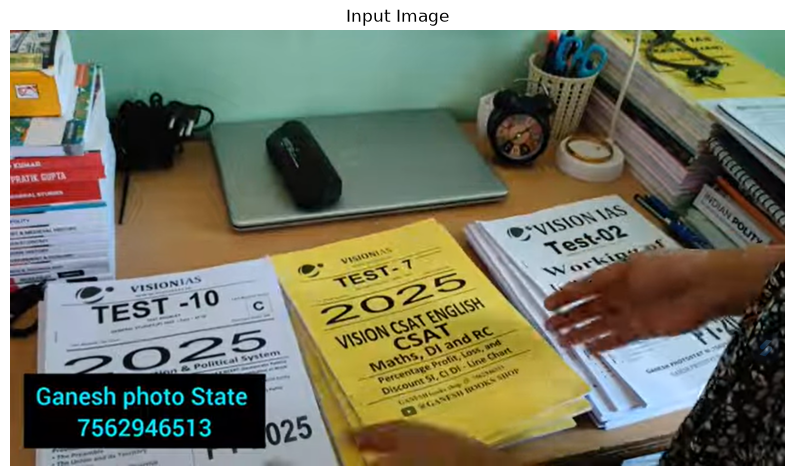

In [17]:
plt.figure(figsize=(10, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Input Image")
plt.show()

In [19]:
# Perform object detection
results = model(image)

print("Inference completed successfully.")


0: 384x640 1 person, 1 laptop, 1 mouse, 7 books, 213.2ms
Speed: 23.1ms preprocess, 213.2ms inference, 16.5ms postprocess per image at shape (1, 3, 384, 640)
Inference completed successfully.


In [21]:
# Get the first result because only one image was provided
result = results[0]

# Extract detection information
boxes = result.boxes

print("Number of detections:", len(boxes))

Number of detections: 10


In [25]:
detection_data = []

for box in boxes:

    # Bounding box coordinates
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    # Confidence score
    confidence = float(box.conf[0].cpu().numpy())

    # Class ID
    class_id = int(box.cls[0].cpu().numpy())

    # Class name
    class_name = model.names[class_id]

    detection_data.append({
        "Object": class_name,
        "Confidence": confidence,
        "X1": int(x1),
        "Y1": int(y1),
        "X2": int(x2),
        "Y2": int(y2)
    })

# Convert detections into a DataFrame
detections_df = pd.DataFrame(detection_data)

detections_dfdetection_data = []

for box in boxes:

    # Bounding box coordinates
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    # Confidence score
    confidence = float(box.conf[0].cpu().numpy())

    # Class ID
    class_id = int(box.cls[0].cpu().numpy())

    # Class name
    class_name = model.names[class_id]

    detection_data.append({
        "Object": class_name,
        "Confidence": confidence,
        "X1": int(x1),
        "Y1": int(y1),
        "X2": int(x2),
        "Y2": int(y2)
    })

# Convert detections into a DataFrame
detections_df = pd.DataFrame(detection_data)

detections_df

,Object,Confidence,X1,Y1,X2,Y2
0,person,0.818783,1325,536,1919,1062
1,book,0.633702,1121,403,1770,987
2,laptop,0.526915,492,190,1240,499
3,book,0.401868,1729,167,1919,379
4,book,0.368891,1729,247,1919,495
5,book,0.351750,642,460,1439,1059
6,book,0.349507,640,410,1790,1059
7,book,0.346861,489,191,1233,497
8,mouse,0.310875,633,222,827,442
9,book,0.267526,1682,363,1918,536


In [27]:
# Create a copy of the original image
output_image = image_rgb.copy()

for detection in detection_data:

    x1 = detection["X1"]
    y1 = detection["Y1"]
    x2 = detection["X2"]
    y2 = detection["Y2"]

    object_name = detection["Object"]
    confidence = detection["Confidence"]

    # Draw bounding box
    cv2.rectangle(
        output_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    # Create label
    label = f"{object_name}: {confidence:.2f}"

    # Draw label
    cv2.putText(
        output_image,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

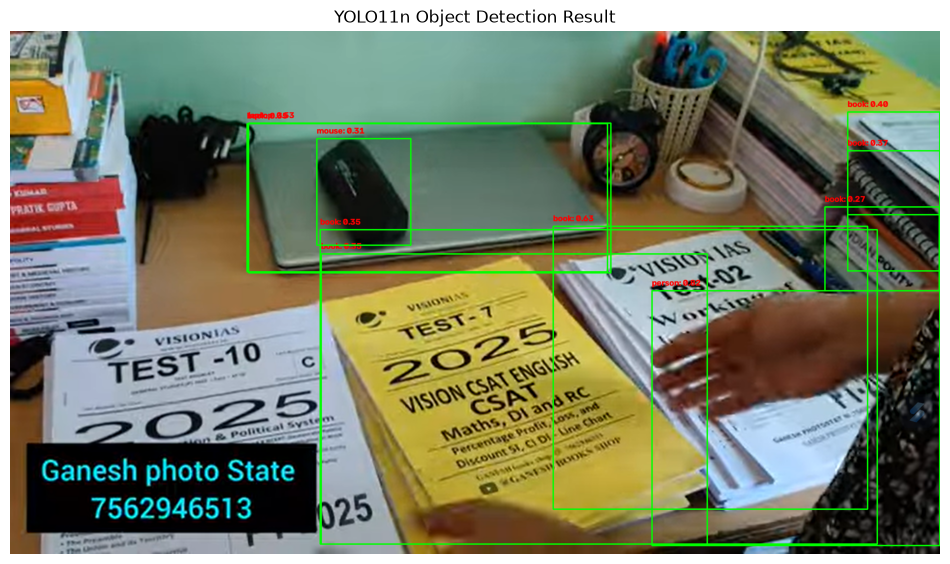

In [29]:
plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("YOLO11n Object Detection Result")
plt.show()

In [31]:
# Count detected objects
object_counts = detections_df["Object"].value_counts()

print("Detected Object Counts:")
print(object_counts)

Detected Object Counts:
Object
book      14
person     2
laptop     2
mouse      2
Name: count, dtype: int64


In [33]:
# Minimum confidence threshold
confidence_threshold = 0.50

filtered_detections = detections_df[
    detections_df["Confidence"] >= confidence_threshold
].copy()

print("Detections after confidence filtering:")
filtered_detections

Detections after confidence filtering:


,Object,Confidence,X1,Y1,X2,Y2
0,person,0.818783,1325,536,1919,1062
1,book,0.633702,1121,403,1770,987
2,laptop,0.526915,492,190,1240,499
10,person,0.818783,1325,536,1919,1062
11,book,0.633702,1121,403,1770,987
12,laptop,0.526915,492,190,1240,499


In [35]:
test_images = [
    r"C:\Users\satis\Downloads\img1.png",
    r"C:\Users\satis\Downloads\img2.jpeg"
]

for image_path in test_images:

    print("=" * 60)
    print("Testing:", image_path)

    if not Path(image_path).exists():
        print("Image not found. Skipping...")
        continue

    test_results = model(image_path)

    print(
        "Number of detections:",
        len(test_results[0].boxes)
    )

Testing: C:\Users\satis\Downloads\img1.png

image 1/1 C:\Users\satis\Downloads\img1.png: 448x640 4 persons, 1 sports ball, 126.0ms
Speed: 2.5ms preprocess, 126.0ms inference, 2.7ms postprocess per image at shape (1, 3, 448, 640)
Number of detections: 5
Testing: C:\Users\satis\Downloads\img2.jpeg

image 1/1 C:\Users\satis\Downloads\img2.jpeg: 640x640 1 tv, 2 laptops, 2 cell phones, 143.6ms
Speed: 4.7ms preprocess, 143.6ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Number of detections: 5


In [37]:
test_summary = []

for image_path in test_images:

    if not Path(image_path).exists():
        continue

    test_results = model(image_path)
    result = test_results[0]

    detected_objects = []

    for box in result.boxes:

        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        detected_objects.append(class_name)

    test_summary.append({
        "Image": image_path,
        "Number of Objects": len(detected_objects),
        "Detected Classes": ", ".join(detected_objects)
    })

test_summary_df = pd.DataFrame(test_summary)

test_summary_df


image 1/1 C:\Users\satis\Downloads\img1.png: 448x640 4 persons, 1 sports ball, 100.2ms
Speed: 8.2ms preprocess, 100.2ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 C:\Users\satis\Downloads\img2.jpeg: 640x640 1 tv, 2 laptops, 2 cell phones, 84.1ms
Speed: 4.4ms preprocess, 84.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


,Image,Number of Objects,Detected Classes
0,C:\Users\satis\Downloads\img1.png,5,"sports ball, person, person, person, person"
1,C:\Users\satis\Downloads\img2.jpeg,5,"laptop, tv, laptop, cell phone, cell phone"


In [7]:
from ultralytics import YOLO
import cv2

# Load the pre-trained YOLO11n model
model = YOLO("yolo11n.pt")

# Open the webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam.")

print("Webcam started.")
print("Press 'q' to stop.")

while True:
    # Capture one frame
    ret, frame = cap.read()

    if not ret:
        print("Failed to capture frame.")
        break

    # Perform YOLO11n object detection
    results = model(frame, verbose=False)

    # Draw bounding boxes, labels and confidence scores
    annotated_frame = results[0].plot()

    # Display the detected frame
    cv2.imshow("YOLO11n - Real-Time Object Detection", annotated_frame)

    # Press q to exit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

# Release webcam
cap.release()
cv2.destroyAllWindows()

Webcam started.
Press 'q' to stop.
